# 06 · Comparación de los 4 modelos en múltiples periodos

Objetivo: la sección 8 del informe técnico elige a XGBoost como mejor modelo por ROC-AUC, pero usando un solo corte train/val (día 100). El profesor preguntó si ese resultado se mantiene si movemos el corte: ¿sigue XGBoost siendo el mejor de los 4 en otros periodos de la línea de tiempo? Se reentrenan los 4 modelos candidatos (notebook 03) en 4 cortes distintos y se compara el ranking por ROC-AUC en cada uno.

In [1]:
import sys
sys.path.append('../src')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

from models import get_models
from evaluation import compute_metrics

train_df = pd.read_parquet('../data/processed/train.parquet')
val_df = pd.read_parquet('../data/processed/val.parquet')
test_df = pd.read_parquet('../data/processed/test.parquet')
full_df = pd.concat([train_df, val_df, test_df], ignore_index=True).sort_values('TransactionDT').reset_index(drop=True)

drop_cols = ['TransactionID', 'isFraud', 'TransactionDT', 'day']
feature_cols = [c for c in full_df.columns if c not in drop_cols]

print('full_df:', full_df.shape, ' dias:', full_df['day'].min(), '-', full_df['day'].max())

full_df: (590540, 401)  dias: 0 - 181


## 1. Diseño del experimento

Se eligen 4 puntos de corte: día 60, 90, 120 y 150, cada uno seguido de un bloque de evaluación de 20 días, el mismo tamaño de ventana que usa el notebook 05 para sus escenarios de olvido. No se reusa el corte día 100 de la sección 8 porque su ventana de evaluación (val, 40 días) es distinta, y mezclar tamaños de ventana le restaría limpieza a la comparación. Se evitan cortes antes del día 60 porque con menos historial el entrenamiento queda con muy pocos datos.

En cada corte los 4 modelos se entrenan con todo el historial disponible (sin ninguna estrategia de olvido, para que la única variable que cambie sea el periodo) y se puntúan con el umbral por defecto de 0.5, igual que la tabla original de la sección 8. La Regresión Logística se entrena sobre variables escaladas con un `StandardScaler` ajustado solo con el historial de cada corte, igual que en el notebook 03.

In [2]:
CUTOFFS = [60, 90, 120, 150]
EVAL_DAYS = 20
THRESHOLD = 0.5

results = []
for cutoff in CUTOFFS:
    history = full_df[full_df['day'] < cutoff]
    eval_block = full_df[(full_df['day'] >= cutoff) & (full_df['day'] < cutoff + EVAL_DAYS)]

    scaler = StandardScaler()
    X_hist_scaled = scaler.fit_transform(history[feature_cols])
    X_eval_scaled = scaler.transform(eval_block[feature_cols])

    for name, model in get_models().items():
        t0 = time.time()
        if name == 'logistic_regression':
            model.fit(X_hist_scaled, history['isFraud'])
            proba = model.predict_proba(X_eval_scaled)[:, 1]
        else:
            model.fit(history[feature_cols], history['isFraud'])
            proba = model.predict_proba(eval_block[feature_cols])[:, 1]
        pred = (proba >= THRESHOLD).astype(int)

        m = compute_metrics(eval_block['isFraud'], pred, proba)
        m['cutoff'] = cutoff
        m['model'] = name
        m['n_train'] = len(history)
        m['n_eval'] = len(eval_block)
        m['train_time_s'] = round(time.time() - t0, 1)
        results.append(m)
        print(f"corte={cutoff}  {name:22s} roc_auc={m['roc_auc']:.4f}  f1={m['f1']:.4f}  ({m['train_time_s']}s)")

results_df = pd.DataFrame(results)
roc_auc_pivot = results_df.pivot(index='cutoff', columns='model', values='roc_auc')
print()
print('ROC-AUC por corte y modelo:')
print(roc_auc_pivot.round(4))
print()
print('Mejor modelo por corte:')
print(roc_auc_pivot.idxmax(axis=1))

C:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


corte=60  logistic_regression    roc_auc=0.8401  f1=0.2485  (111.5s)


corte=60  random_forest          roc_auc=0.8791  f1=0.3981  (112.9s)


[LightGBM] [Info] Number of positive: 6978, number of negative: 216760


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.362393 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 32966
[LightGBM] [Info] Number of data points in the train set: 223738, number of used features: 395
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


corte=60  lightgbm               roc_auc=0.9052  f1=0.4648  (65.6s)


... (20 outputs left out)

corte=150  lightgbm               roc_auc=0.9096  f1=0.3411  (36.6s)


corte=150  xgboost                roc_auc=0.9084  f1=0.4975  (71.7s)



ROC-AUC por corte y modelo:
model   lightgbm  logistic_regression  random_forest  xgboost
cutoff                                                       
60        0.9052               0.8401         0.8791   0.9186
90        0.8984               0.8274         0.8674   0.9011
120       0.9252               0.8453         0.8842   0.9206
150       0.9096               0.8257         0.8743   0.9084

Mejor modelo por corte:


cutoff
60      xgboost
90      xgboost
120    lightgbm
150    lightgbm
dtype: object


El resultado es más parejo de lo que sugería el corte único de la sección 8. XGBoost gana por ROC-AUC en 2 de los 4 cortes (día 60 y 90), y LightGBM en los otros 2 (día 120 y 150). Los márgenes son chicos en los 4 casos, entre 0.12 y 1.34 puntos porcentuales de ROC-AUC. El ranking entre los dos modelos de ensamble más fuertes no es absoluto, aunque sí es consistente que ambos superan claramente a Random Forest y Regresión Logística en los 4 cortes, sin excepción.

Esto responde directamente a la pregunta del profesor: mover el periodo de evaluación sí cambia cuál de los dos mejores modelos gana, prácticamente mitad y mitad en esta muestra de 4 cortes. El resultado general de la sección 8, que los modelos de boosting (LightGBM y XGBoost) superan a la línea base clásica, se mantiene estable en los 4 periodos evaluados, pero la elección específica de XGBoost como "el mejor modelo" depende del periodo que se mire, y no se puede sostener como un resultado absoluto.

## 2. Comparación visual

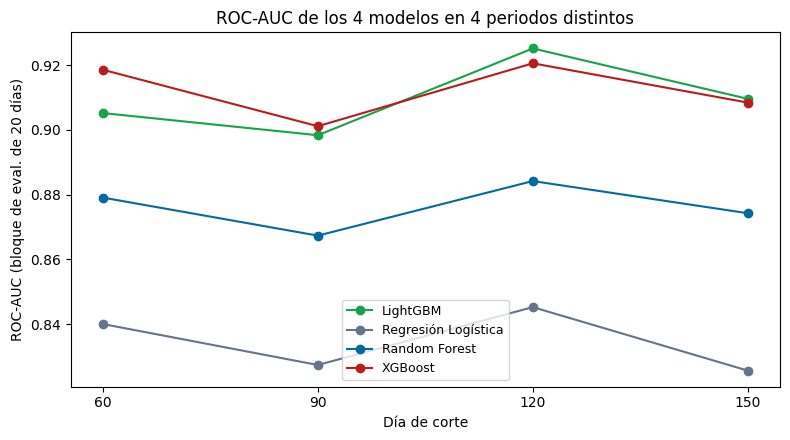

In [3]:
colors = {'logistic_regression': '#64748b', 'random_forest': '#0369a1', 'lightgbm': '#16a34a', 'xgboost': '#b91c1c'}
labels = {'logistic_regression': 'Regresión Logística', 'random_forest': 'Random Forest', 'lightgbm': 'LightGBM', 'xgboost': 'XGBoost'}

fig, ax = plt.subplots(figsize=(8, 4.5))
for model_name in roc_auc_pivot.columns:
    ax.plot(roc_auc_pivot.index, roc_auc_pivot[model_name], marker='o', label=labels[model_name], color=colors[model_name])

ax.set_xlabel('Día de corte')
ax.set_ylabel('ROC-AUC (bloque de eval. de 20 días)')
ax.set_title('ROC-AUC de los 4 modelos en 4 periodos distintos')
ax.set_xticks(CUTOFFS)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('../figures/09_multi_period_model_comparison.png', dpi=110)
plt.show()

![Comparación multi-periodo](../figures/09_multi_period_model_comparison.png)

Las líneas de LightGBM y XGBoost quedan claramente por encima de Random Forest y Regresión Logística en los 4 cortes, y las dos suben o bajan juntas de un corte a otro, lo que sugiere que responden al mismo factor externo (probablemente la dificultad relativa de cada bloque de 20 días) más que a una diferencia estructural entre ambos algoritmos. El cruce ocurre entre el corte día 90 y el día 120: XGBoost va adelante en los primeros dos cortes, y LightGBM se mantiene arriba en los últimos dos.

## Conclusiones

- XGBoost gana por ROC-AUC en 2 de los 4 cortes evaluados (día 60, 90); LightGBM gana en los otros 2 (día 120, 150). Los márgenes son chicos en los 4 casos.
- La brecha entre los modelos de boosting (LightGBM, XGBoost) y la línea base clásica (Random Forest, Regresión Logística) es grande y estable en los 4 periodos, sin ninguna excepción.
- La elección de XGBoost en la sección 8 se basa en un solo corte y no se sostiene como un resultado absoluto: en la mitad de los periodos evaluados aquí, LightGBM habría sido la mejor opción. El sistema debería monitorear periódicamente cuál de los dos modelos de boosting rinde mejor, en vez de asumir que el modelo ganador es fijo para siempre.